In [5]:
import yaml
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import PyComplexHeatmap as pch

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']  # Syntax: sym_cellline_replicate
cell_line_colors=config['cell_line_colors']

In [6]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']
path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

# Stats of counts per guide

In [8]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'Supplementary_Table_1_SYM101_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,865,787,762,652,1532,864,758,669,475,478


In [9]:
# the lowest we ever detect any guide in Pools is 217
gmin = df.loc[:, pools].min(1).min()
df_ = df.loc[:, pools].min(1).reset_index()
df_['NT guide'] = df.index.isin(controls)

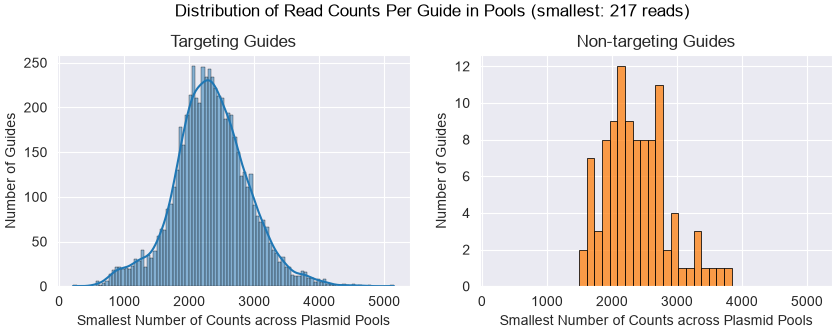

In [10]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharex=True)
ax = axs[0]
sns.histplot(df_[~df_['NT guide']], x=0, bins=100, kde=True, color='tab:blue', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title('Targeting Guides')

ax = axs[1]
sns.histplot(df_[df_['NT guide']], x=0, bins=20, kde=False, color='tab:orange', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title(f'Non-targeting Guides')

pl.suptitle(f'Distribution of Read Counts Per Guide in Pools (smallest: {gmin} reads)', y=1.05)
pl.savefig('../results/qc_plots/hist_read_counts_per_guide_in_plasmid_pools.pdf', bbox_inches='tight')
pl.show()

In [11]:
# Guides per gene distribution
cell_line = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})


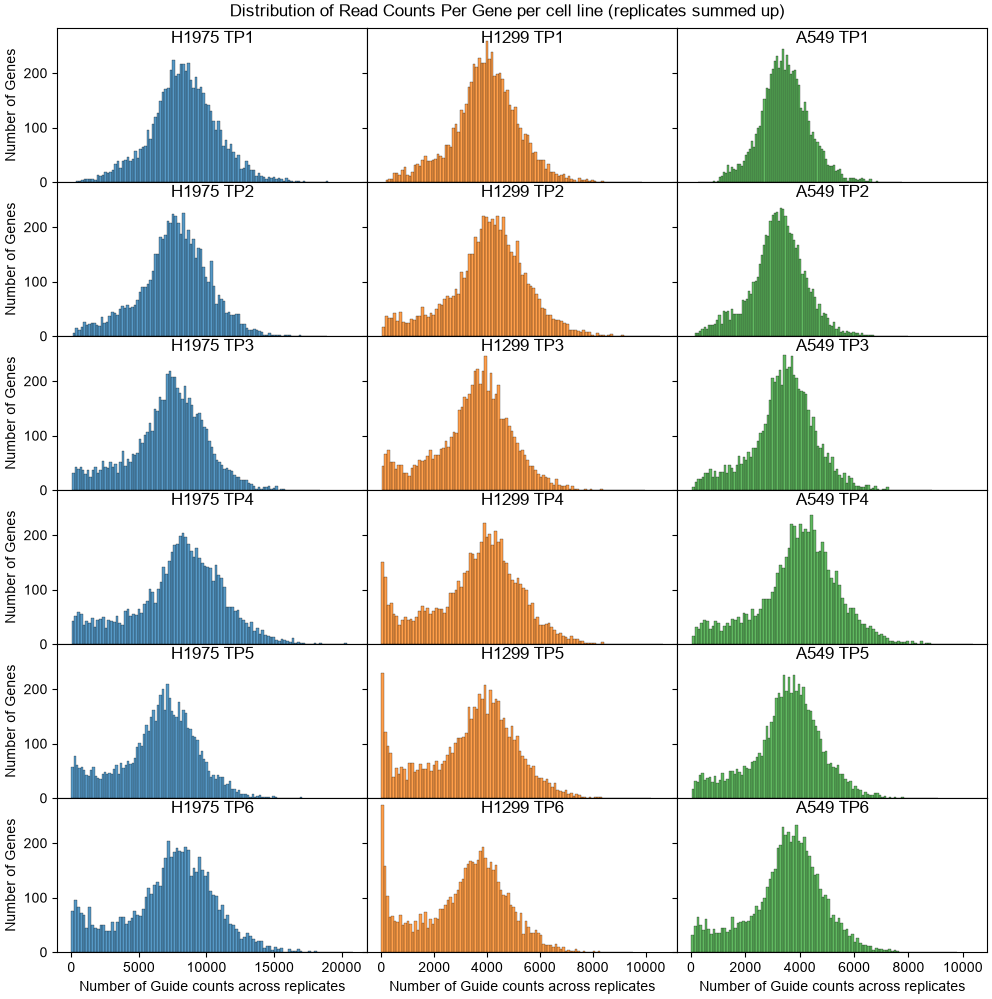

In [13]:
fig, axss = pl.subplots(6, 3, figsize=(4*3, 2*6), sharex='col', sharey=True, gridspec_kw={'hspace': 0, 'wspace': 0})
axss=axss
for i, cl in enumerate(['H1975', 'H1299', 'A549']):
    for j, tp in enumerate(['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']):
        ax = axss[j, i]
        sample = sample_names[(time_point == tp) & (cell_line == cl)]
        df_ = df.loc[:, sample].sum(1)
        sns.histplot(df_, bins=100, color=cell_line_colors[cl], label='Non-targeting Guides', ax=ax)
        ax.set_xlabel('Number of Guide counts across replicates')
        ax.set_ylabel('Number of Genes')
        ax.set_title(f'{cl} {tp}', y=0.85)
pl.suptitle(f'Distribution of Read Counts Per Gene per cell line (replicates summed up)', y=0.90)
pl.savefig('../results/qc_plots/hist_read_counts_per_gene.pdf', bbox_inches='tight')
pl.show()

# Correlation between guides targeting the same target

In [15]:
# Load Data
df = pd.read_csv(Path(config['TEMPDIR']) / 'Supplementary_Table_1_SYM101_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
l2fc['Transcript_ID'] = df.Transcript_ID.copy()
l2fc['Gene'] = df.Gene.copy()

In [17]:
l2fc.drop('Transcript_ID', axis=1).groupby('Gene').corr().mean(1).reset_index().groupby('Gene').mean('0')

,0
Gene,
AATBC,0.467428
ACKR2,0.564371
ACTA2-AS1,0.202240
ACTB,0.840836
ACTG1,0.856543
...,...
ZNF728,0.286443
ZNF93,0.350073
ZNHIT2,0.088266


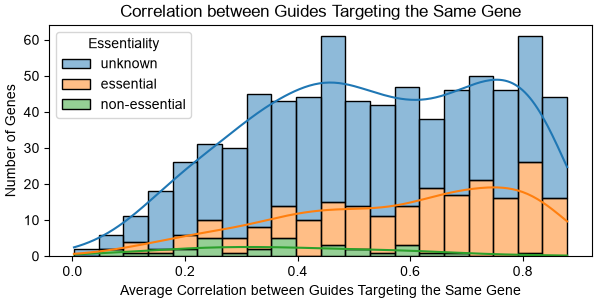

In [18]:
# Calculate the correlation between guides targeting the same gene
corr = l2fc.drop('Transcript_ID', axis=1).groupby('Gene').corr().mean(1).reset_index().groupby('Gene').mean('0')
corr['essential'] = annotate_essentiality(corr.index)
corr.rename(columns={0: 'Correlation'}, inplace=True)
fig, ax = pl.subplots(figsize=(7, 3))
sns.histplot(corr, x='Correlation', bins=20, kde=True, hue='essential', multiple="stack", ax=ax)
ax.set_xlabel('Average Correlation between Guides Targeting the Same Gene')
ax.set_ylabel('Number of Genes')
ax.set_title('Correlation between Guides Targeting the Same Gene')
ax.legend_.set_title('Essentiality')
pl.savefig('../results/qc_plots/hist_correlation_between_guides_per_gene.pdf', bbox_inches='tight')
pl.show()

# Evaluate guide counting /alignment to screen

In [19]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc.cell_line.replace({f'0{x}': y for x, y in cell_line_dict.items()}, inplace=True)
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc[['Mapped (with MQ>0)', 'MQ0', 'Unmapped']].sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

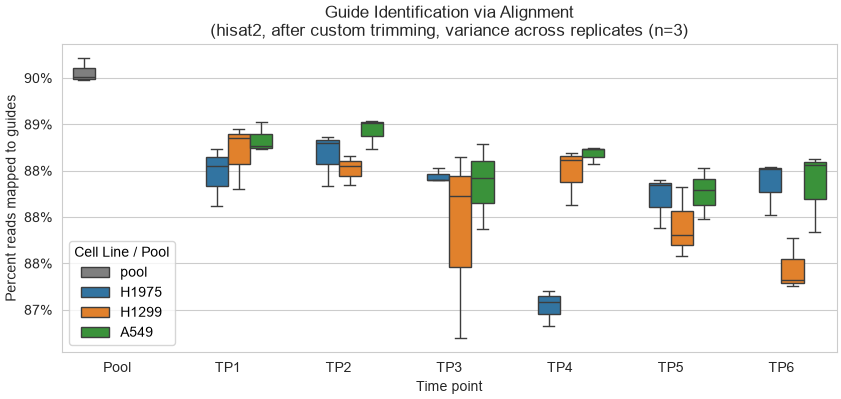

In [20]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(10,4))
sns.boxplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True, palette=config['cell_line_colors'])
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/qc_plots/qc_mapping_guide_alignment.pdf', bbox_inches='tight')
pl.legend(loc='lower left', title='Cell Line / Pool')
pl.show()

# Sample Correlation

In [22]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'Supplementary_Table_1_SYM101_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [23]:
# Calculate pairwise correlations between samples
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

In [ ]:
# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

# Explicit, shared timepoint colors so this heatmap and the fold-change heatmaps
# below use identical colors per timepoint (Blues gradient TP1->TP6, white for
# the plasmid pool TP0). Passed via colors= (a dict) so the mapping is fixed by
# label and does not depend on which timepoints are present in a given figure.
blues = sns.color_palette('Blues', as_cmap=True)
tp_levels = ['TP0', 'TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']
time_point_colors = {tp: blues(x) for tp, x in zip(tp_levels, np.linspace(0.2, 0.9, 7))}
time_point_colors['TP0'] = (1, 1, 1, 1)  # white for plasmid pool

annot_kwargs = dict(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, colors=cell_line_colors),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, colors=time_point_colors),
    verbose=0, plot_legend=False
)
top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)

pl.figure(figsize=(14, 12))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300, bbox_inches='tight')
pairwise_correlations.to_csv('../results/qc_plots/qc_correlation_source_data.csv')
pl.show()

# Sample correlation on fold-changes (gRNA- and target-level)

Raw read-count correlations (above) are dominated by the shared composition of the screening library and are high by construction, regardless of condition. The informative replicate QC is the correlation of (log2) **fold-changes** relative to the plasmid pool, both at the **gRNA** level and collapsed to the **target (transcript)** level. These cells recompute `l2fc` self-contained (NT-depth normalized, vs plasmid pool) and report the mean within-line, between-replicate correlation at the final timepoint (TP6).

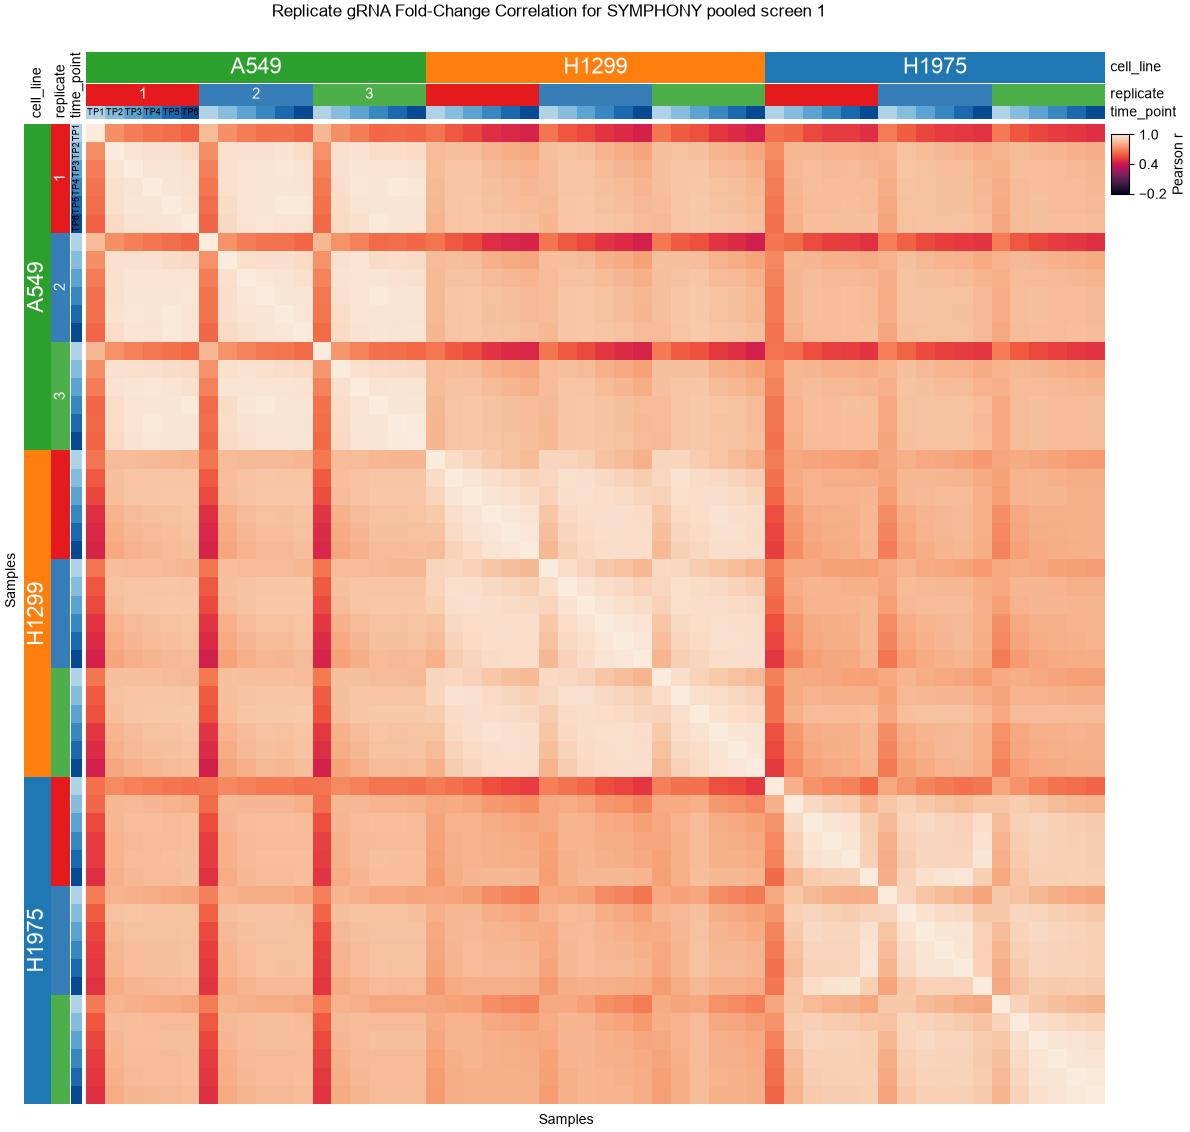

In [34]:
# Recompute per-guide log2 fold-change vs plasmid pool (NT-depth normalized),
# self-contained so this section does not depend on earlier cells.
df = pd.read_csv(Path(config['TEMPDIR']) / 'Supplementary_Table_1_SYM101_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = np.sort(['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2'])
controls = [x for x in df.index if 'control' in x.lower()]
timecourse = np.array([x for x in sample_names if 'pool' not in x.lower()])  # exclude plasmid pools

norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor
l2fc = np.log2((ndf.T / ndf.loc[:, pools].mean(axis=1)).T)
l2fc = l2fc.replace([np.inf, -np.inf], np.nan)
l2fc['Transcript_ID'] = df.Transcript_ID.values

# Sample annotation, shared by both fold-change heatmaps
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] for x in timecourse})
replicate = pd.Series({x: x.split('-')[2][-1] for x in timecourse})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in timecourse})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index

# Explicit, shared timepoint colors so these fold-change heatmaps use the same
# color per timepoint as the raw-count heatmap above (Blues gradient TP1->TP6,
# white reserved for the plasmid pool TP0, which is absent here). Passed via
# colors= (a dict) so each label maps to a fixed color.
blues = sns.color_palette('Blues', as_cmap=True)
tp_levels = ['TP0', 'TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']
time_point_colors = {tp: blues(x) for tp, x in zip(tp_levels, np.linspace(0.2, 0.9, 7))}
time_point_colors['TP0'] = (1, 1, 1, 1)  # white for plasmid pool


def fc_correlation_heatmap(mat, title, outstem):
    """mat: features (guides or transcripts) x samples. Pearson corr of fold-changes between samples."""
    corr = mat.loc[:, timecourse].corr(method='pearson', min_periods=50)
    data = corr.loc[order, order]
    annot_kwargs = dict(
        cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, colors=cell_line_colors),
        replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
        time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, colors=time_point_colors),
        verbose=0, plot_legend=False)
    top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
    left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)
    pl.figure(figsize=(14, 12))
    pch.ClusterMapPlotter(
        data=data, left_annotation=left_ha, top_annotation=top_ha,
        row_cluster=False, col_cluster=False, label='r',
        row_dendrogram=False, col_dendrogram=False, legend_gap=7,
        rasterized=True, cmap='rocket', vmin=-0.2, vmax=1,
        legend_kws=dict(label='Pearson r'), xlabel='Samples', ylabel='Samples',
        legend_hpad=0, verbose=0)
    pl.suptitle(title, y=0.92)
    pl.savefig(f'../results/qc_plots/{outstem}.png', dpi=300)
    pl.savefig(f'../results/qc_plots/{outstem}.pdf', dpi=300, bbox_inches='tight')
    corr.to_csv(f'../results/qc_plots/{outstem}_source_data.csv')
    return corr

# (1) gRNA-level fold-change correlation
guide_corr = fc_correlation_heatmap(
    l2fc,
    'Replicate gRNA Fold-Change Correlation for SYMPHONY pooled screen 1',
    'qc_correlation_heatmap_guide_l2fc')
pl.show()

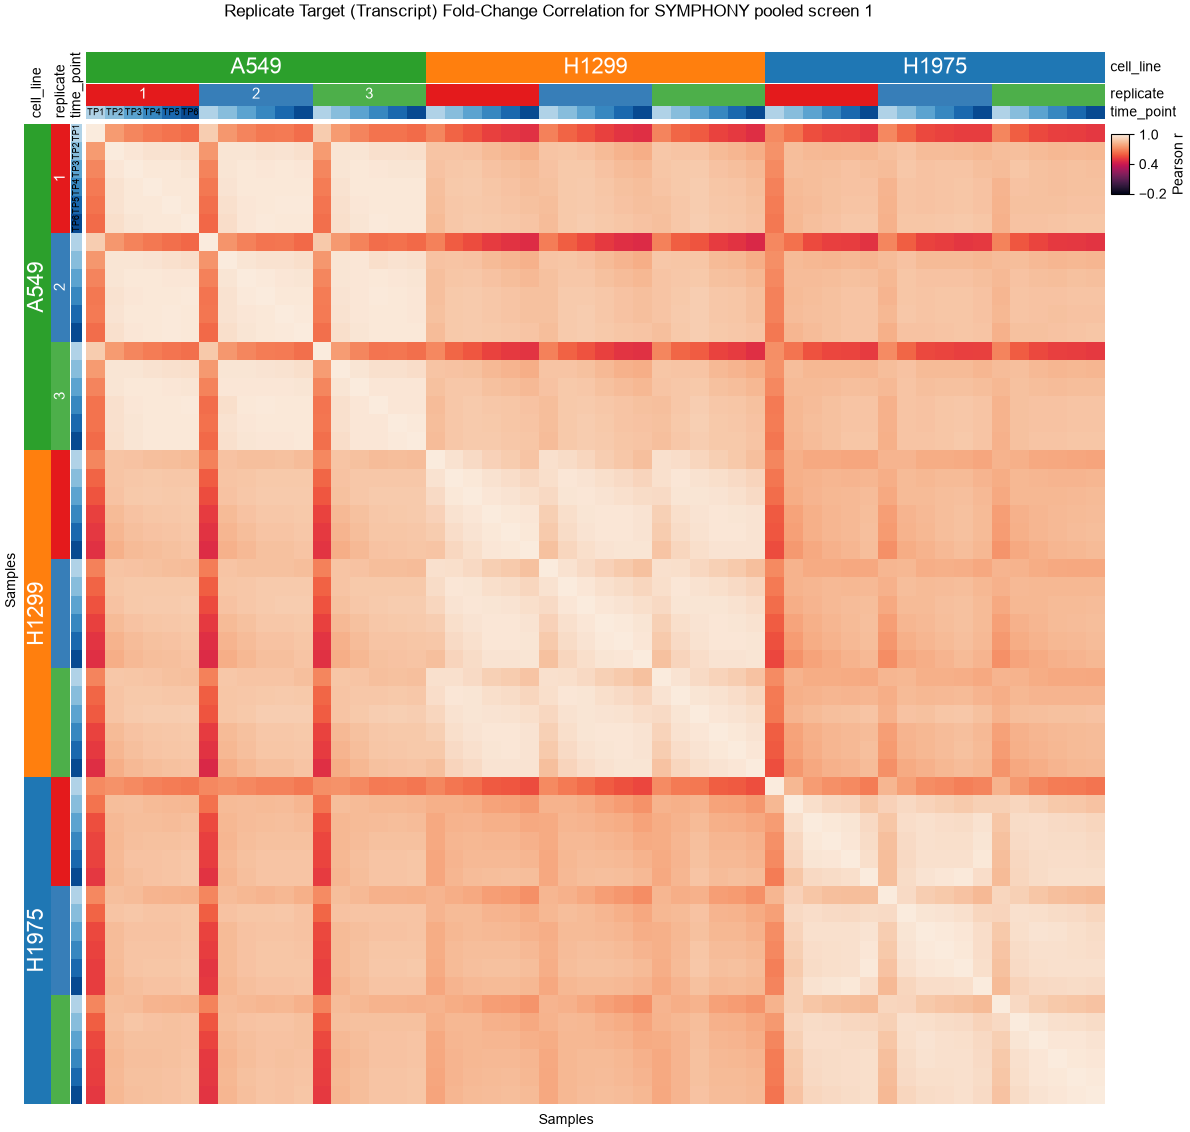

In [35]:
# (2) Target-level fold-change correlation: collapse guides to their transcript (mean l2fc)
transcript_l2fc = l2fc.groupby('Transcript_ID')[list(timecourse)].mean()
transcript_corr = fc_correlation_heatmap(
    transcript_l2fc,
    'Replicate Target (Transcript) Fold-Change Correlation for SYMPHONY pooled screen 1',
    'qc_correlation_heatmap_transcript_l2fc')
pl.show()

In [28]:
# Headline QC table (replaces the raw-count 0.91 metric): mean within-line,
# between-replicate correlation at the final timepoint (TP6), for raw counts vs
# gRNA fold-change vs target-level (transcript) fold-change.
rawcount_corr = df[timecourse].corr(method='pearson')  # original metric, for comparison

def mean_replicate_corr(corr, tp='TP6'):
    rows = []
    for line in cell_line_dict.values():
        cols = [c for c in timecourse if cell_line[c] == line and time_point[c] == tp]
        sub = corr.loc[cols, cols].values
        iu = np.triu_indices(len(cols), k=1)  # off-diagonal replicate pairs
        rows.append({'cell_line': line, 'n_replicates': len(cols), 'mean_r': sub[iu].mean()})
    return pd.DataFrame(rows)

summary = pd.concat([
    mean_replicate_corr(rawcount_corr).assign(level='raw counts (original)'),
    mean_replicate_corr(guide_corr).assign(level='gRNA fold-change'),
    mean_replicate_corr(transcript_corr).assign(level='target (transcript) fold-change'),
], ignore_index=True)
summary.to_csv('../results/qc_plots/qc_replicate_correlation_summary.csv', index=False)
print(summary.to_string(index=False))
print('\nAverage across cell lines at TP6:')
print(summary.groupby('level', sort=False).mean_r.mean().round(3).to_string())

cell_line  n_replicates   mean_r                           level
    H1975             3 0.837490           raw counts (original)
    H1299             3 0.929622           raw counts (original)
     A549             3 0.961117           raw counts (original)
    H1975             3 0.903780                gRNA fold-change
    H1299             3 0.957887                gRNA fold-change
     A549             3 0.976973                gRNA fold-change
    H1975             3 0.953364 target (transcript) fold-change
    H1299             3 0.977430 target (transcript) fold-change
     A549             3 0.987886 target (transcript) fold-change

Average across cell lines at TP6:
level
raw counts (original)              0.909
gRNA fold-change                   0.946
target (transcript) fold-change    0.973
